In [30]:
import torch
import random

In [31]:
n_way = 5
k_shot = 1
q_query = 5

In [32]:
background_root='./omniglot/python/images_background'
evaluation_root='./omniglot/python/images_evaluation'

In [33]:
from functools import partial
import sys
from tqdm import tqdm as origin_tqdm

tqdm = partial(origin_tqdm, file=sys.stdout, ncols=100)

In [34]:
from pathlib import Path

background_path = Path(background_root)
alphabet_paths = [p for p in background_path.iterdir() if p.is_dir()]
selected_alphabet_paths = random.sample(alphabet_paths, round(len(alphabet_paths) * 0.2))

train_path = background_path / 'train'
val_path = background_path / 'val'

train_root = train_path.as_posix()
val_root = val_path.as_posix()

if not val_path.exists():
    train_path.mkdir(exist_ok=True)
    val_path.mkdir(exist_ok=True)

    for alphabet_path in selected_alphabet_paths:
        alphabet_path.move_into(val_path)

    for alphabet_path in background_path.iterdir():
        if alphabet_path.is_dir() and alphabet_path not in [train_path, val_path]:
            alphabet_path.move_into(train_path)

In [35]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

device

device(type='cuda')

In [36]:
from pathlib import Path
from typing import Iterator, override

from torch import Tensor
import torch.nn as nn
from torch.utils.data import IterableDataset
from torchvision.io import decode_image


class EpisodeDataset(IterableDataset):
    def __init__(self, root: str, n_way: int, k_shot: int, q_query: int, transform: nn.Module | None = None) -> None:
        super().__init__()

        self.root = root
        self.n_way = n_way
        self.k_shot = k_shot
        self.q_query = q_query
        self.transform = transform

        self.alphabet_to_characters_to_images: dict[str, dict[str, list[Tensor]]] = {}

        self._load()

    def _load(self) -> None:
        root_path = Path(self.root)

        for alphabet_path in root_path.iterdir():
            if not alphabet_path.is_dir():
                continue

            for character_path in alphabet_path.iterdir():
                if not character_path.is_dir():
                    continue

                for image_path in character_path.iterdir():
                    if not image_path.is_file():
                        continue

                    image = self._load_image(image_path.as_posix())

                    self.alphabet_to_characters_to_images.setdefault(alphabet_path.as_posix(), {}).setdefault(character_path.as_posix(), []).append(image)

        if len(self.alphabet_to_characters_to_images) == 0:
            raise ValueError(f'Must have at least one character with images in {self.root}')

        # print(self.alphabet_to_characters_to_images[r'omniglot/python/images_background/Alphabet_of_the_Magi/character01'])

    def _load_image(self, path_str: str) -> Tensor:
        image = decode_image(path_str)

        if self.transform:
            image = self.transform(image)

        image: Tensor = image.float() / 255

        return image

    @override
    def __iter__(self) -> Iterator[tuple[Tensor, Tensor, Tensor, Tensor]]:
        while True:
            # 选中的字母表下的所有字符
            # {'omniglot/python/images_background/Alphabet_of_the_Magi/character01': [T...], ...}
            selected_characters_to_images = random.choice(tuple(self.alphabet_to_characters_to_images.values()))

            # 选中的字母表下的n_way个字符
            # [Tensor, Tensor, ...]
            selected_images = random.sample(tuple(selected_characters_to_images.values()), self.n_way) 

            # print(selected_characters_to_images, selected_images.__len__(), selected_images[0].__len__())

            support_list: list[Tensor] = []
            support_labels_list: list[int] = []
            query_list: list[Tensor] = []
            query_labels_list: list[int] = []

            for i, images in enumerate(selected_images):
                images: list[Tensor] = random.sample(images, self.k_shot + self.q_query)

                support_list += images[: self.k_shot]
                support_labels_list += [i] * self.k_shot
                query_list += images[self.k_shot :]
                query_labels_list += [i] * self.q_query

            support = torch.stack(support_list)
            support_labels = torch.tensor(support_labels_list)
            query = torch.stack(query_list)
            query_labels = torch.tensor(query_labels_list)

            yield support, support_labels, query, query_labels

In [37]:
class Encoder(nn.Module):
    def __init__(self, in_channels=1, feature_channels=64, embed_dim=64) -> None:
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(feature_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(feature_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(feature_channels, embed_dim, 3, padding=1),
            nn.BatchNorm2d(embed_dim),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1)  # (batch, embed_dim, 1, 1)
        )

    def forward(self, x: Tensor):
        x = self.encoder(x)
        return x.view(x.size(0), -1)  # flatten to (batch, embed_dim)

In [38]:
class ProtoNet(nn.Module):
    def __init__(self, encoder: nn.Module) -> None:
        super().__init__()

        self.encoder: nn.Module = encoder

    def forward(self, support: Tensor, support_labels: Tensor, query: Tensor) -> Tensor:
        '''
        support: (n_way*k_shot, 1, H, W)
        support_labels: (n_way*k_shot,)
        query: (n_way*q_query, 1, H, W)

        return:
            logits: (n_way*q_query, n_way)
        '''
        # 1. embed support and query
        embed_support: Tensor = self.encoder(support)  # (n_way*k_shot, embed_dim)
        embed_query: Tensor = self.encoder(query)  # (n_way*q_query, embed_dim)

        # 2. compute prototypes
        unique_labels = torch.unique(support_labels)  # [0,1,2,...,n_way-1]
        prototypes_list = []
        for c in unique_labels:
            # mean of embeddings for class c
            embed_class = embed_support[support_labels == c]
            prototypes_list.append(embed_class.mean(0))

        prototypes: Tensor = torch.stack(prototypes_list)  # (n_way, embed_dim)

        # 3. compute negative distances as logits
        # dist: (n_query, n_way)
        dist = torch.cdist(embed_query, prototypes) ** 2

        # negative distance = higher score if closer
        logits = -dist

        return logits

In [39]:
train_set = EpisodeDataset(root=train_root, n_way=n_way, k_shot=k_shot, q_query=q_query)
val_set = EpisodeDataset(root=val_root, n_way=n_way, k_shot=k_shot, q_query=q_query)
test_set = EpisodeDataset(root=evaluation_root, n_way=n_way, k_shot=k_shot, q_query=q_query)

In [40]:
from torch.utils.data import DataLoader

train_loader: DataLoader[Tensor] = DataLoader(train_set, batch_size=None)
val_loader: DataLoader[Tensor] = DataLoader(val_set, batch_size=None)
test_loader: DataLoader[Tensor] = DataLoader(test_set, batch_size=None)

In [41]:
encoder = Encoder(in_channels=1, feature_channels=64, embed_dim=64)
model = ProtoNet(encoder).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay = 1e-4)
loss_fn = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    patience=5,
    factor=0.5,
)

In [42]:
epochs = 250
batches = 512
val_batches = 512
early_stop_patience = 25

best_val_loss = float('inf')
no_improve_epochs = 0

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for i, (support, support_labels, query, query_labels) in tqdm(enumerate(train_loader), total=batches, desc=f'Epoch {epoch:3d}'):
        if i >= batches:
            break

        support: Tensor = support.to(device)  # (n_way*k_shot, 1, H, W)
        query: Tensor = query.to(device)  # (n_way*q_query, 1, H, W)
        support_labels: Tensor = support_labels.to(device)
        query_labels: Tensor = query_labels.to(device)

        optimizer.zero_grad()

        logits: Tensor = model(support, support_labels, query)
        loss: Tensor = loss_fn(logits, query_labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    model.eval()

    val_total_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for i, (support, support_labels, query, query_labels) in tqdm(enumerate(val_loader), total=val_batches, desc='      Val', leave=False):
            if i >= val_batches:
                break

            support: Tensor = support.to(device)
            query: Tensor = query.to(device)
            support_labels: Tensor = support_labels.to(device)
            query_labels: Tensor = query_labels.to(device)

            logits: Tensor = model(support, support_labels, query)
            loss: Tensor = loss_fn(logits, query_labels)

            val_total_loss += loss.item()

            pred_labels = logits.argmax(dim=1)
            val_correct += (pred_labels == query_labels).sum().item()
            val_total += query_labels.size(0)

    val_loss = val_total_loss / val_batches
    val_accuracy = val_correct / val_total

    lrs = [param_group['lr'] for param_group in optimizer.param_groups]

    print(f'           Train Loss: {total_loss/batches} | Val Loss: {val_loss} | Val Accuracy: {val_accuracy} | LR: {lrs}')

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        no_improve_epochs = 0
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        no_improve_epochs += 1

        if no_improve_epochs > early_stop_patience:
            print('Early stopping triggered')
            break

    torch.save(model.state_dict(), 'last_model.pth')

Epoch   0: 100%|██████████████████████████████████████████████████| 512/512 [00:11<00:00, 43.81it/s]
           Train Loss: 1.0287140720756724 | Val Loss: 0.7700871204724535 | Val Accuracy: 0.73109375 | LR: [0.01]
Epoch   1: 100%|██████████████████████████████████████████████████| 512/512 [00:11<00:00, 44.81it/s]
           Train Loss: 0.6382984012798261 | Val Loss: 0.5331836513132657 | Val Accuracy: 0.835859375 | LR: [0.01]
Epoch   2: 100%|██████████████████████████████████████████████████| 512/512 [00:11<00:00, 44.83it/s]
           Train Loss: 0.4517809036424296 | Val Loss: 0.4069081623736608 | Val Accuracy: 0.8725 | LR: [0.01]
Epoch   3: 100%|██████████████████████████████████████████████████| 512/512 [00:11<00:00, 45.65it/s]
           Train Loss: 0.31547113007150074 | Val Loss: 0.3564815303790283 | Val Accuracy: 0.892578125 | LR: [0.01]
Epoch   4: 100%|██████████████████████████████████████████████████| 512/512 [00:11<00:00, 45.87it/s]
           Train Loss: 0.29019807145732557 |

In [43]:
model.load_state_dict(torch.load('best_model.pth'))

<All keys matched successfully>

In [44]:
test_batches = 1024

model.eval()

test_total_loss = 0
test_correct = 0
test_total = 0

with torch.no_grad():
    for i, (support, support_labels, query, query_labels) in tqdm(enumerate(test_loader), total=test_batches, desc='Test'):
        if i >= test_batches:
            break

        support: Tensor = support.to(device)
        query: Tensor = query.to(device)
        support_labels: Tensor = support_labels.to(device)
        query_labels: Tensor = query_labels.to(device)

        logits: Tensor = model(support, support_labels, query)
        loss: Tensor = loss_fn(logits, query_labels)

        test_total_loss += loss.item()

        pred_labels = logits.argmax(dim=1)
        test_correct += (pred_labels == query_labels).sum().item()
        test_total += query_labels.size(0)

    test_loss = test_total_loss / test_batches
    test_accuracy = test_correct / test_total

    print(f'Test Loss: {test_loss} | Test Accuracy: {test_accuracy}')

Test: 100%|████████████████████████████████████████████████████| 1024/1024 [00:07<00:00, 134.09it/s]
Test Loss: 0.3552309557271566 | Test Accuracy: 0.91171875


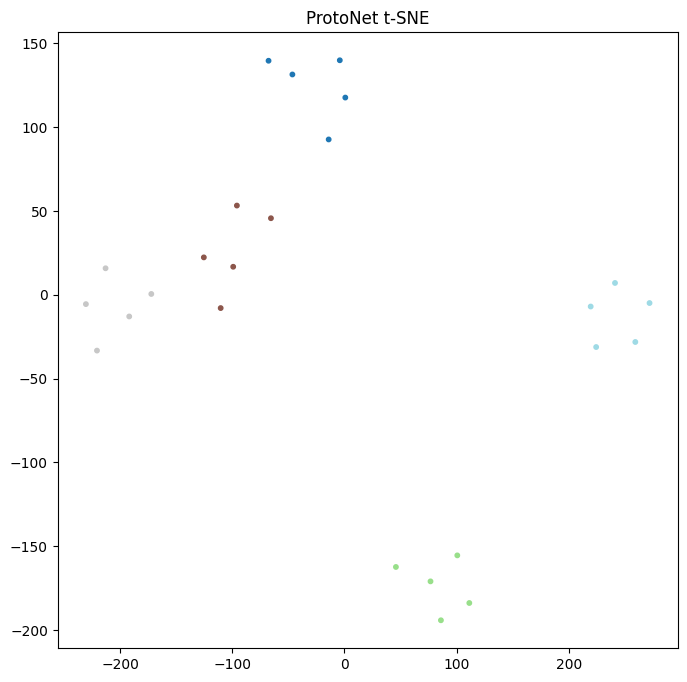

In [45]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

embeddings = []
labels = []

model.eval()

with torch.no_grad():
    for i, (support, support_labels, query, query_labels) in enumerate(test_loader):
        if i >= 1:
            break

        query = query.to(device)

        embed = model.encoder(query)

        embeddings.append(embed.cpu())
        labels.append(query_labels)

embeddings = torch.cat(embeddings)
labels = torch.cat(labels)

tsne = TSNE(n_components=2, perplexity=5)
embeddings_2d = tsne.fit_transform(embeddings.numpy())

plt.figure(figsize=(8,8))
plt.scatter(embeddings_2d[:,0], embeddings_2d[:,1], c=labels, cmap="tab20", s=10)
plt.title("ProtoNet t-SNE")
plt.show()